In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("outputs.csv")

A = df.iloc[:, 0]
B = df.iloc[:, 1]
Cin = df.iloc[:, 2]
R_0 = df.iloc[:, 3]
R = df.iloc[:, 3:20]

R_ex = A+B+Cin

error_conv = R_0 - R_ex
print("Errores:", np.count_nonzero(error_conv))
print("Error máximo:", np.max(np.abs(error_conv)))


Errores: 0
Error máximo: 0


In [ ]:
# Calcular errores restando R_0 a cada columna de R
Error = R.sub(R_ex, axis=0)

# Obtener el valor absoluto de todos los errores
ErrorAbs = np.abs(Error)

print("Dimensiones de la matriz de errores absolutos:", ErrorAbs.shape)
#display(ErrorAbs.head())

Dimensiones de la matriz de errores absolutos: (131071, 17)


In [ ]:
# Calcular el número de errores (valores diferentes de cero) por columna
cantidad_errores = (ErrorAbs != 0).sum()

# Calcular la tasa de errores (porcentaje de error)
tasa_errores = (cantidad_errores / len(ErrorAbs)) * 100

In [ ]:
#erroe medio asoluto
MED = ErrorAbs.mean()
#display(MED)

In [ ]:
#mayor error absoluto
WCE = ErrorAbs.max()
#display(WCE)

In [ ]:
ME = Error.mean()
#display(ME)
#Revisar tendencia

In [ ]:
# Crear un DataFrame para mostrar los resultados de manera ordenada
resumen_errores = pd.DataFrame({
    'Errores Cometidos': cantidad_errores,
    'Tasa de Error (%)': tasa_errores,
    'Error Medio Absoluto': MED,
    'Mayor Error Absoluto': WCE,
    'Error Medio': ME
})
display(resumen_errores)

,Errores Cometidos,Tasa de Error (%),Error Medio Absoluto,Mayor Error Absoluto,Error Medio
0.3,0,0.000000,0.000000,0,0.0
0.4,32768,25.000191,0.250002,1,0.0
0.5,49152,37.500286,0.562504,3,0.0
0.6,61440,46.875358,1.109383,7,0.0
0.7,71680,54.687917,2.183610,15,0.0
0.8,80384,61.328593,4.331088,31,0.0
0.9,87808,66.992699,8.629705,63,0.0
0.10,94144,71.826720,17.231272,127,0.0
0.11,99552,75.952728,34.438419,255,0.0
0.12,65536,50.000381,0.500004,1,0.0


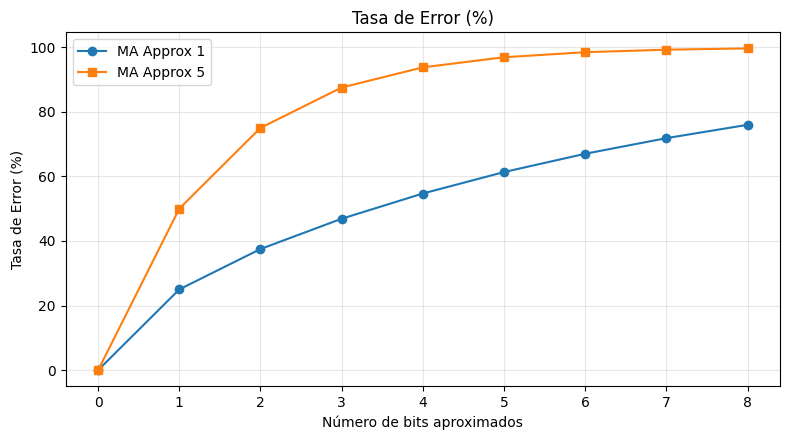

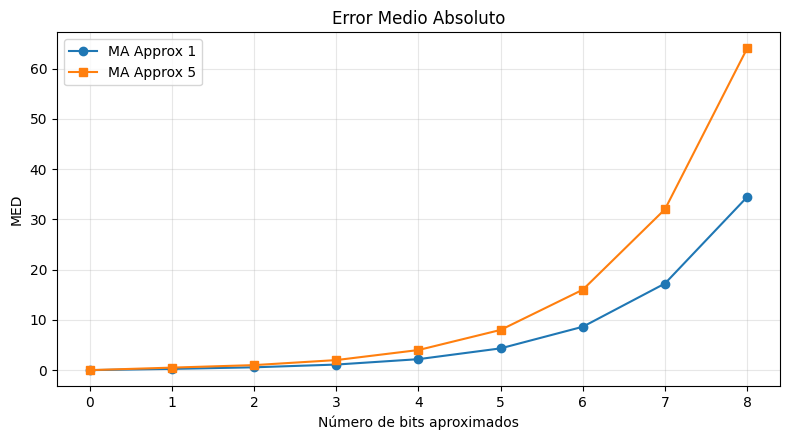

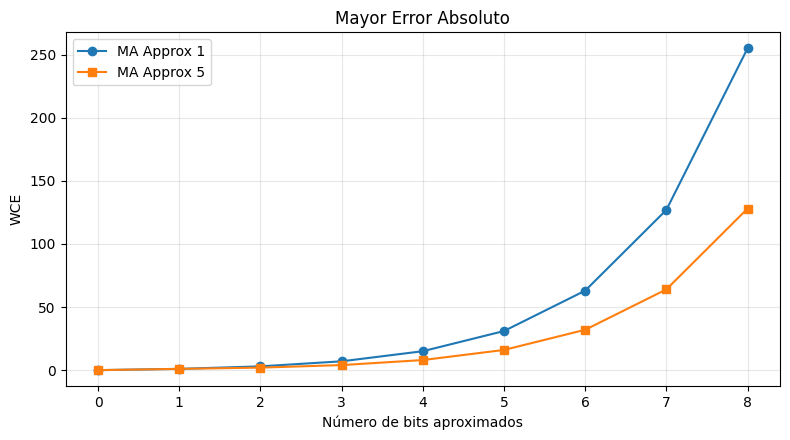

In [ ]:
bits = np.arange(9)

metricas = [
    ("Tasa de Error (%)", "Tasa de Error (%)"),
    ("Error Medio Absoluto", "MED"),
    ("Mayor Error Absoluto", "WCE")
]

for metrica, ylabel in metricas:

    familia1 = resumen_errores[metrica].iloc[0:9]

    familia5 = np.concatenate([
        resumen_errores[metrica].iloc[0:1],
        resumen_errores[metrica].iloc[9:17]
    ])

    plt.figure(figsize=(8, 4.5))

    plt.plot(bits, familia1, "o-", label="MA Approx 1")
    plt.plot(bits, familia5, "s-", label="MA Approx 5")

    plt.title(metrica)
    plt.xlabel("Número de bits aproximados")
    plt.ylabel(ylabel)

    plt.xticks(bits)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()